In [2]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, optimizers

ModuleNotFoundError: No module named 'tensorflow.python'

In [ ]:
image_dir = r"C:\Users\ASUS\Desktop\University\5th\utkface\UTKFace"
IMG_SIZE = 128
cnn_images, cnn_ages = [], []

for filename in os.listdir(image_dir):
    if filename.endswith(".jpg"):
        try:
            age = int(filename.split("_")[0])
            if 0 <= age <= 90:
                img = cv2.imread(os.path.join(image_dir, filename))
                img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
                gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
                norm_gray = gray.astype(np.float32) / 255.0
                cnn_images.append(norm_gray)
                cnn_ages.append(age / 90.0)
        except Exception as e:
            print(f"Skipping {filename}: {e}")

cnn_images = np.expand_dims(np.array(cnn_images), axis=-1)
cnn_ages = np.array(cnn_ages)

x_train, x_test, y_train, y_test = train_test_split(cnn_images, cnn_ages, test_size=0.2, random_state=42)

def denormalize_age(normalized_age):
    return normalized_age * 90.0

print("CNN data shape:", cnn_images.shape)
print("CNN ages range (normalized):", cnn_ages.min(), cnn_ages.max())


CNN data shape: (23621, 128, 128, 1)
CNN ages range (normalized): 0.011111111111111112 1.0


In [ ]:
    cnn_model = models.Sequential([
        layers.Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE,1)),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(64, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(128, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(256, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Conv2D(512, (3,3), activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(2,2),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1)
    ])

    lr_schedule = optimizers.schedules.ExponentialDecay(
        initial_learning_rate=1e-3,
        decay_steps=1000,
        decay_rate=0.9
    )

    cnn_model.compile(
        optimizer=optimizers.Adam(learning_rate=lr_schedule),
        loss='mean_squared_error',
        metrics=['mae']
    )

In [ ]:
NOISE_DIM = 100
def build_generator():
    model = tf.keras.Sequential([
        layers.Dense(8*8*256, use_bias=False, input_shape=(NOISE_DIM,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),
        layers.Reshape((8,8,256)),

        layers.Conv2DTranspose(128, 5, strides=2, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),   # (16x16)

        layers.Conv2DTranspose(64, 5, strides=2, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),   # (32x32)

        layers.Conv2DTranspose(32, 5, strides=2, padding='same', use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),   # (64x64)

        layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh")  # (128x128x1)
    ])
    return model


In [ ]:
def build_discriminator():
    model = tf.keras.Sequential([
        layers.Conv2D(64, 5, strides=2, padding='same', input_shape=[IMG_SIZE, IMG_SIZE, 1]),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128, 5, strides=2, padding='same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1)
    ])
    return model

generator = build_generator()
discriminator = build_discriminator()

cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
gen_optimizer = tf.keras.optimizers.Adam(1e-4)
disc_optimizer = tf.keras.optimizers.Adam(1e-4)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    return cross_entropy(tf.ones_like(real_output), real_output) + \
           cross_entropy(tf.zeros_like(fake_output), fake_output)

In [ ]:
    BATCH_SIZE = 64
    EPOCHS_GAN = 30

    dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(10000).batch(BATCH_SIZE)

    @tf.function
    def train_step(images):
        noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])
        with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
            generated = generator(noise, training=True)
            real_output = discriminator(images, training=True)
            fake_output = discriminator(generated, training=True)
            gen_loss = generator_loss(fake_output)
            disc_loss = discriminator_loss(real_output, fake_output)
        grads_gen = gen_tape.gradient(gen_loss, generator.trainable_variables)
        grads_disc = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
        gen_optimizer.apply_gradients(zip(grads_gen, generator.trainable_variables))
        disc_optimizer.apply_gradients(zip(grads_disc, discriminator.trainable_variables))
        return gen_loss, disc_loss

    for epoch in range(EPOCHS_GAN):
        for image_batch in dataset:
            g_loss, d_loss = train_step(image_batch)
        print(f"GAN Epoch {epoch+1}/{EPOCHS_GAN} - Gen Loss: {g_loss.numpy():.4f}, Disc Loss: {d_loss.numpy():.4f}")

In [ ]:
NUM_GAN_IMAGES = 500
gan_imgs, gan_ages = [], []

for _ in range(NUM_GAN_IMAGES):
    noise = tf.random.normal([1, NOISE_DIM])
    fake_img = generator(noise, training=False).numpy()[0]
    fake_img_scaled = ((fake_img + 1) / 2.0).astype(np.float32)  
    gan_imgs.append(fake_img_scaled)  
    gan_ages.append(np.random.rand())  

gan_imgs = np.array(gan_imgs)  
gan_ages = np.array(gan_ages)

x_train_aug = np.concatenate([x_train, gan_imgs], axis=0)
y_train_aug = np.concatenate([y_train, gan_ages], axis=0)
print("Augmented training data shape:", x_train_aug.shape)


In [ ]:
cnn_history = cnn_model.fit(
    x_train_aug, y_train_aug,
    validation_data=(x_test, y_test),
    epochs=30,
    batch_size=32
)
cnn_model.save("cnn_utk_model.h5")
generator.save("gan_generator.h5")
discriminator.save("gan_discriminator.h5")


In [ ]:
from tensorflow.keras.models import load_model

cnn_model = load_model(r"C:\Users\ASUS\AppData\Local\Programs\Microsoft VS Code\cnn_utk_model.h5")


In [ ]:
loss, mae = cnn_model.evaluate(x_test, y_test, verbose=0)
print(f"Final Test Loss (MSE): {loss:.4f}")
print(f"Final Test MAE: {mae:.4f}")


Final Test Loss (MSE): 0.0087
Final Test MAE: 0.0697


In [ ]:

def test_random_dataset_sample(cnn_model, x_data, y_data):
    idx = np.random.randint(0, len(x_data))
    img = x_data[idx]
    true_age = denormalize_age(y_data[idx])
    img_input = np.expand_dims(img, axis=0)
    pred_norm = cnn_model.predict(img_input, verbose=0)[0][0]
    pred_age = denormalize_age(pred_norm)
    print(f"True Age: {round(true_age,1)}, Predicted Age: {round(pred_age,1)}")
    plt.imshow(img[:,:,0], cmap='gray')
    plt.title(f"True: {round(true_age,1)}, Pred: {round(pred_age,1)}")
    plt.axis('off')
    plt.show()

True Age: 26.0, Predicted Age: 25.2


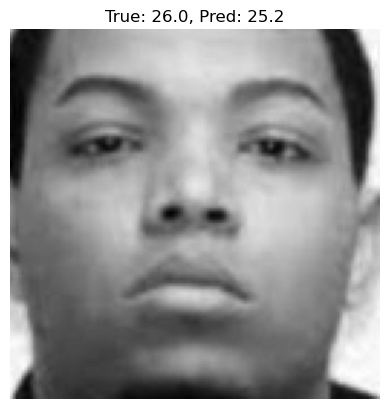

In [ ]:
test_random_dataset_sample(cnn_model, x_test, y_test)


True Age: 28.0, Predicted Age: 30.6


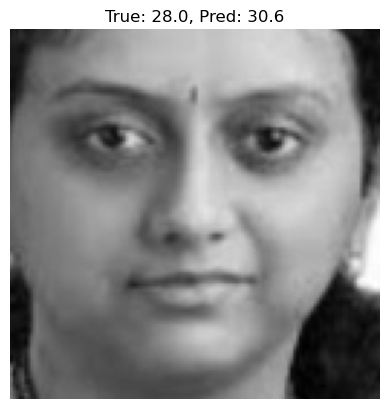

In [ ]:
test_random_dataset_sample(cnn_model, x_test, y_test)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

def denormalize_age(normalized_age):
    return normalized_age * 90.0

    
def test_random_dataset_sample(cnn_model, x_data, y_data):
    idx = np.random.randint(0, len(x_data))
    img = x_data[idx]
    true_age = denormalize_age(y_data[idx])
    img_input = np.expand_dims(img, axis=0)

    pred_norm = cnn_model.predict(img_input, verbose=0)[0][0]
    pred_age = denormalize_age(pred_norm)

    print(f"True Age: {round(true_age,1)}, Predicted Age: {round(pred_age,1)}")
    plt.imshow(img[:,:,0], cmap='gray')
    plt.title(f"True: {round(true_age,1)}, Pred: {round(pred_age,1)}")
    plt.axis('off')
    plt.show()


def predict_custom_image(cnn_model, image_path, IMG_SIZE=128):
    img = cv2.imread(image_path)
    img_resized = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    norm_gray = gray.astype(np.float32) / 255.0
    norm_gray = np.expand_dims(norm_gray, axis=-1)  
    img_input = np.expand_dims(norm_gray, axis=0)   

    pred_norm = cnn_model.predict(img_input, verbose=0)[0][0]
    pred_age = denormalize_age(pred_norm)

    plt.imshow(gray, cmap='gray')
    plt.title(f"Predicted Age: {round(pred_age,1)}")
    plt.axis('off')
    plt.show()

    return pred_age


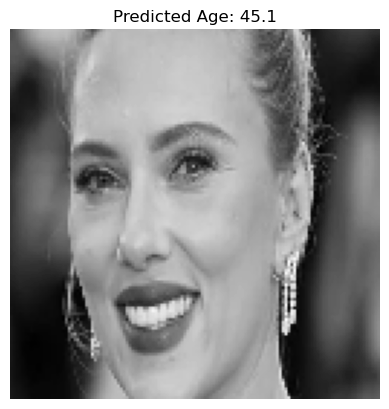

Predicted Age: 45.052319169044495


In [ ]:
predicted = predict_custom_image(cnn_model, r"C:\Users\ASUS\Desktop\picture to test\5.webp")
print("Predicted Age:", predicted)


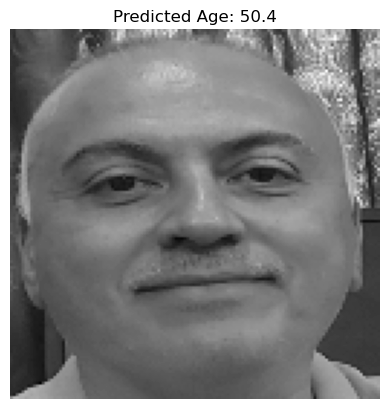

Predicted Age: 50.427857637405396


In [ ]:
predicted = predict_custom_image(cnn_model, r"C:\Users\ASUS\Desktop\photo_2025-09-09_10-17-45.jpg")
print("Predicted Age:", predicted)


In [ ]:
predicted = predict_custom_image(cnn_model, r"c:\Users\Rafe1O1\Pictures\Camera Roll\photo_٢٠٢٦-٠٢-١٦_١٧-٥٥-٣٤.jpg")
print("Predicted Age:", predicted)